# Learned drum decoration for group fitness music

*Generative AI for Music, University of Amsterdam.*

**Group 3**: Giacomo Grazia, Sönke Erdmann and Arshana Ramautar

---

This notebook explains the project, plays the generated drums and shows the results. All code lives in `src/`;
the notebook only imports it. Heavy results (trained models, the 30 loops per system, the result tables and
figures) were produced by `python -m src.train` and `python -m src.evaluate` and are loaded from `output/`, so the
notebook runs top to bottom in seconds without a GPU. The dataset (3 MB) downloads automatically on first run.

# 0. Imports

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
from IPython.display import Audio, Image, Markdown, display
from scipy.signal import resample_poly

from src.config import CHECKPOINT_DIR, CLASSES, DECORATION_CHANNELS, LISTEN_SEEDS, OUTPUT_DIR, SEEDS, skeleton_loop
from src.data import load_bars
from src.generate import add_fill, lstm_loop, rule_loop, rule_probabilities
from src.metrics import density
from src.plot_style import apply_style, decorate
from src.plots import plot_grid

apply_style()
RESULTS, AUDIO = OUTPUT_DIR / "results", OUTPUT_DIR / "audio"
LOOPS = dict(np.load(RESULTS / "loops.npz"))  # system -> (30 loops, 128 steps, 9 drums); B-D per training seed


def play(name: str, label: str = "", folder=AUDIO) -> None:
    """Show a label and an audio player for <folder>/<name>.wav (clips: 15 s, 8 bars at 128 BPM).

    Embedded at half the sample rate (22.05 kHz) to keep the notebook small; the full-quality WAVs are in output/audio.
    """
    if label:
        display(Markdown(f"**{label}**"))
    audio, sr = sf.read(folder / f"{name}.wav")
    display(Audio(resample_poly(audio, 1, 2), rate=sr // 2))


def show_loop(loop: np.ndarray, title: str, subtitle: str = "") -> None:
    """Draw one 8-bar loop (128, 9) as a drum grid."""
    fig, ax = plt.subplots(figsize=(14, 3.4))
    plot_grid(loop, ax=ax)
    decorate(fig, title, subtitle=subtitle)
    plt.show()

# 1. The idea

**Aesthetic goal: steady for the body, alive for the ear.** Workout drums whose pulse never wavers, so a class can
move as one, but whose groove keeps shifting like a human drummer playing for the room, rather than one bar looping
like a drum machine.

Group fitness needs both halves. *Steady*: an instructor cues moves on the beat, and a class of thirty people only
moves together if the kick lands on every beat and the snare on 2 and 4, without exception. *Alive*: a class lasts an
hour, and a single bar looped for an hour is tiring to listen to. Human drummers solve this by repeating a groove
and varying it in small ways, more at the end of a phrase.

We split the drums into two parts:

- the **skeleton**: kick on every beat ("four on the floor") and snare on beats 2 and 4. This must be reliable.
- the **decoration**: hi-hats, toms, crash and ride. This is where variation lives.

**Research question:** with kick and snare fixed, does a model trained on human drumming produce more varied drums
than hand-written rules? It has two parts:

| Part | Comparison | "Yes" means |
|---|---|---|
| **Steady:** do we need the constraint to keep the pulse? | free model B vs constrained model C | B's exact-bar rate is clearly below 100% |
| **Alive:** is the constrained model more varied than rules? | rules A vs constrained model C, at similar density | C changes over time more like real drumming than A (repeats bars, varies in bursts), its diversity is not lower, it does not just play more notes, and listeners find it more interesting |

**Four systems**, all on 8-bar loops at 128 BPM, 30 loops each (seeds 0-29):

| System | What it does |
|---|---|
| **A. Rules** | Skeleton + hand-written probabilities for hats, toms and cymbals |
| **B. LSTM free** | A small LSTM trained on human drumming generates every drum |
| **C. LSTM constrained** | The same LSTM, but kick and snare are forced to the skeleton during generation; it chooses only the decoration |
| **D. Fine-tuned, constrained** | The LSTM after extra training on four-on-the-floor bars, generating as C |

B and C are the *same model, same data, same seeds*; only the constraint changes. That isolates one variable.

**Resources reviewed and not used in the core.** *Drums RNN* (Magenta) is the architecture we match (section 4),
but it depends on old TensorFlow/Magenta versions and a separate environment. *Deep Drum* is a JavaScript demo
built on Drums RNN. *Metacreation* projects gave dataset ideas. *AudioCraft/MusicGen* generate audio directly: heavy
compute and little control over where the beat falls, which is the one thing we must control.

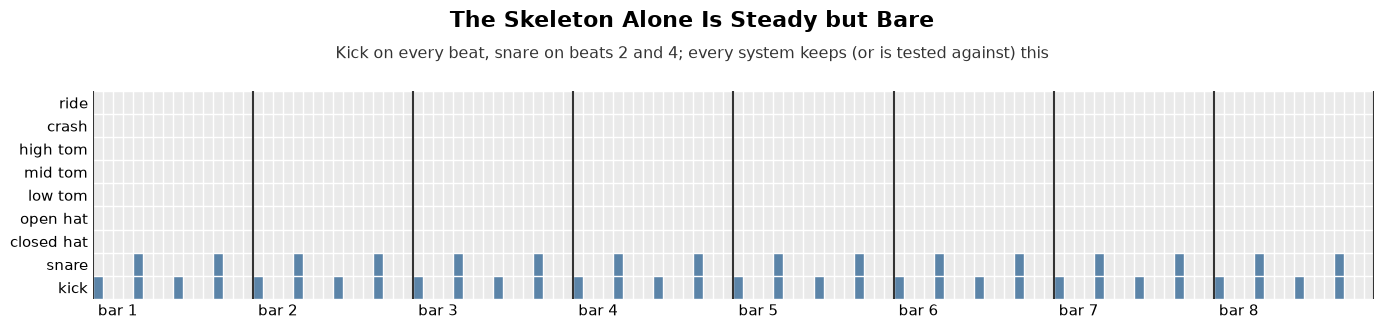

In [2]:
show_loop(skeleton_loop(), "The Skeleton Alone Is Steady but Bare",
          subtitle="Kick on every beat, snare on beats 2 and 4; every system keeps (or is tested against) this")

# 2. The data

We train on the **Groove MIDI Dataset** (GMD; Gillick et al. 2019, "Learning to Groove with Inverse Sequence
Transformations", CC BY 4.0): 1,150 MIDI recordings of ten drummers on an electronic kit, about 13.6 hours. We use
the **official train/validation/test split** and keep only 4/4 grooves (no fills, no other time signatures).

**Representation.** Every hit is snapped to the nearest 16th note using the recording's tempo, and the kit's 22
sounds are grouped into 9 drums (the dataset's own reduced mapping, the same 9 as Drums RNN). A bar becomes a
16 x 9 grid of 0/1: *was this drum hit on this 16th note?* Empty bars at the start and end of each recording
(count-ins) are trimmed.

**What this discards**, and we say so up front:
- **microtiming**: on average a hit sits 17% of a 16th away from its grid line; swing and shuffle (triplet feels)
  are distorted most;
- **velocity**: quiet ghost notes and loud accents become the same hit. This matters for the snare, which averages
  5.2 hits per bar in the data against 2 in our skeleton;
- tempo: all generated loops play at 128 BPM, although most recordings were played at 80-140 BPM.

A longer tour of the data, with more figures and examples, is in [data_analysis/README.md](data_analysis/README.md).

In [3]:
info, bars = load_bars()
summary = (info.groupby("split").agg(recordings=("n_bars", "size"), bars=("n_bars", "sum"))
           .loc[["train", "validation", "test"]])
print(f"{len(info)} recordings (4/4 grooves), {info.n_bars.sum():,} bars after trimming "
      f"({info.trimmed_bars.sum():,} empty edge bars removed, {info.unmappable.sum()} unmappable notes, "
      f"{info.after_last_bar.sum():,} notes after the last complete bar dropped)")
display(summary)

train_bars = np.concatenate([bars[i] for i in info.index[info.split == "train"]])  # (n_bars, 16, 9)
d_gmd = density(train_bars)
per_drum = pd.Series(train_bars.sum(axis=1).mean(axis=0), index=CLASSES).round(2)
print(f"d_GMD = mean decoration hits per bar (channels 2-8, training bars) = {d_gmd:.2f}")
display(per_drum.to_frame("hits per bar").T)

491 recordings (4/4 grooves), 20,597 bars after trimming (1,251 empty edge bars removed, 0 unmappable notes, 2,941 notes after the last complete bar dropped)


,recordings,bars
split,,
train,368,16454
validation,46,2039
test,77,2104


d_GMD = mean decoration hits per bar (channels 2-8, training bars) = 9.96


,kick,snare,closed_hat,open_hat,low_tom,mid_tom,high_tom,crash,ride
hits per bar,3.79,5.18,5.09,0.65,0.45,0.23,0.64,0.28,2.61


**One example before and after quantization.** Orange dots are the moments the drummer actually played; blue
squares are the 16th-note cells they snap to.

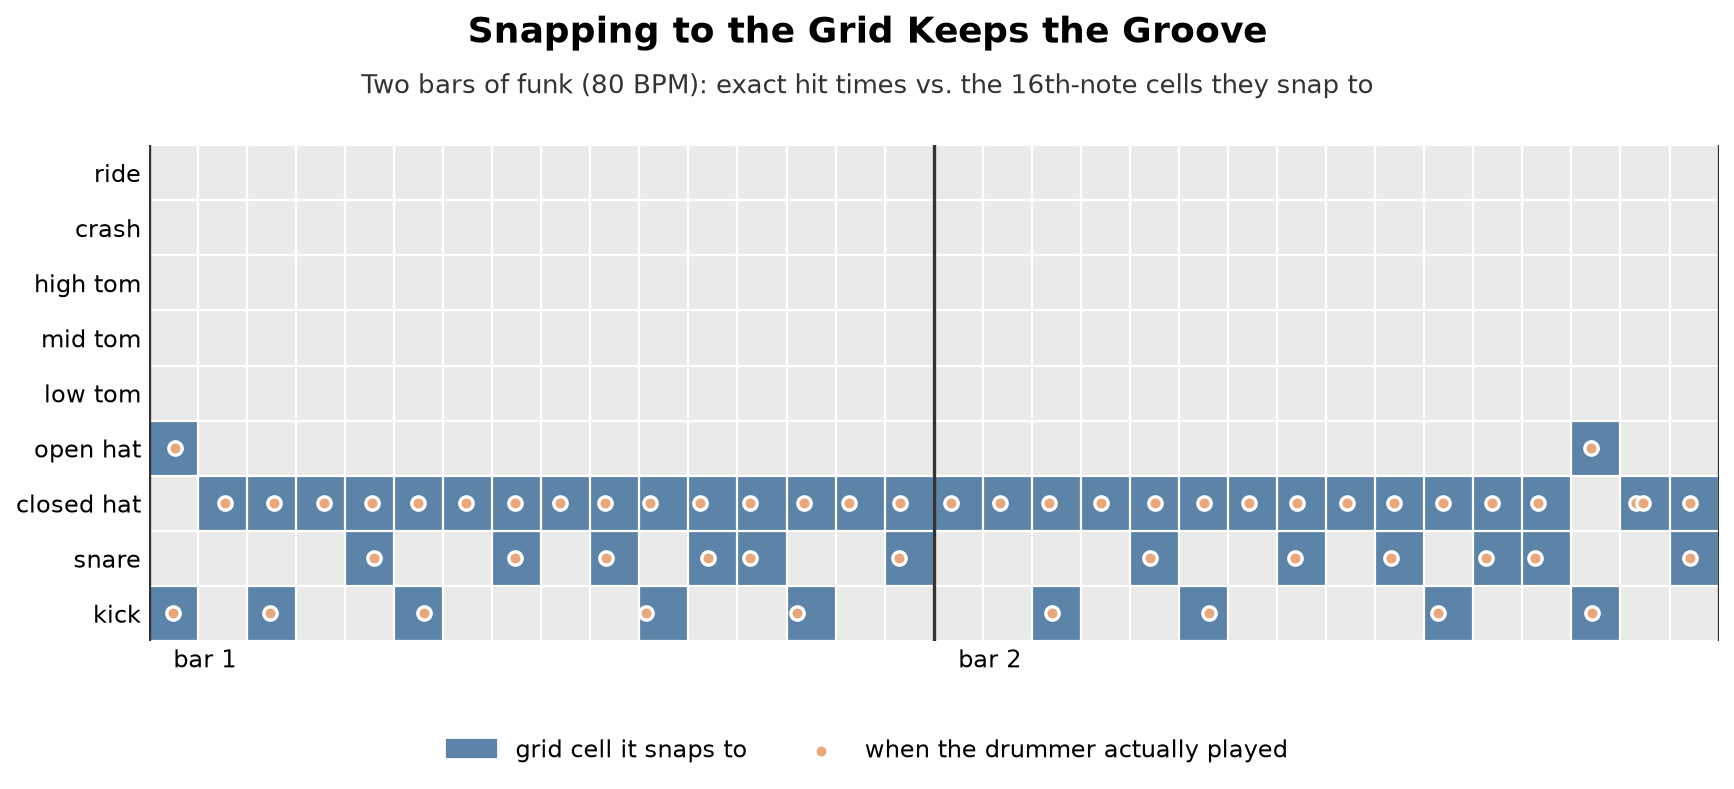

In [4]:
display(Image(filename="data_analysis/figures/quantization.png", width=800))

**Where in the bar drummers play.** The snare half of our skeleton matches the data (snare on 2 and 4 in about 6 of
10 bars), but the kick half does not: drummers mostly play kick on 1 and 3, and only 16% of bars have a kick on all
four beats. Only about 1% of GMD bars match the full skeleton exactly. A model that imitates this data will not
play four on the floor by itself; this is the starting point for section 5.

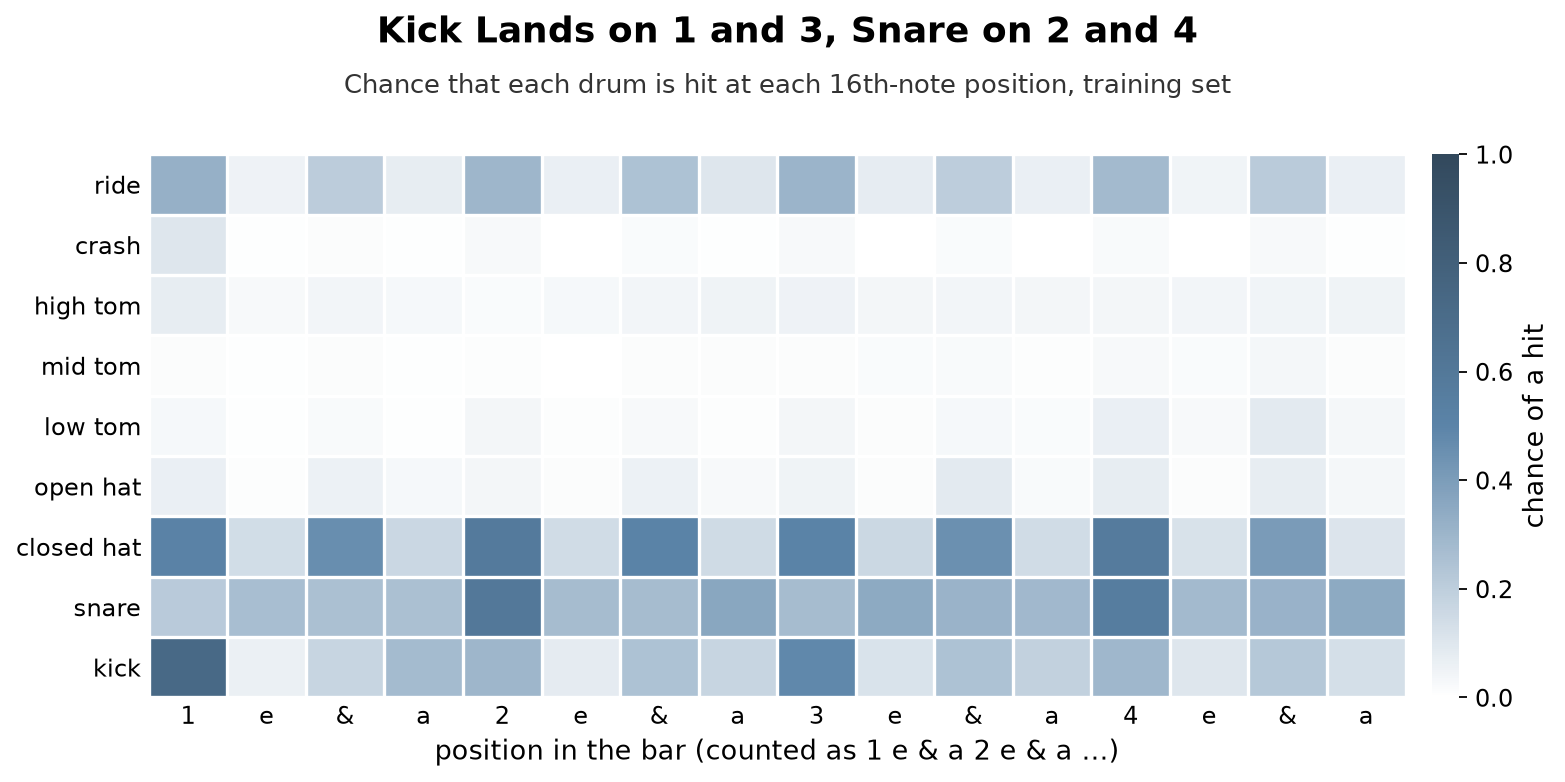

In [5]:
display(Image(filename="data_analysis/figures/where_in_bar.png", width=700))

**Listen to real drumming** after quantization (rock, first training recording of the style with at least 10 bars,
at the drummer's own tempo, rendered with our simple synth at fixed velocity, so it sounds more mechanical than the
original). Note the snare on beat 3: a half-time feel that a fitness class cannot step to.

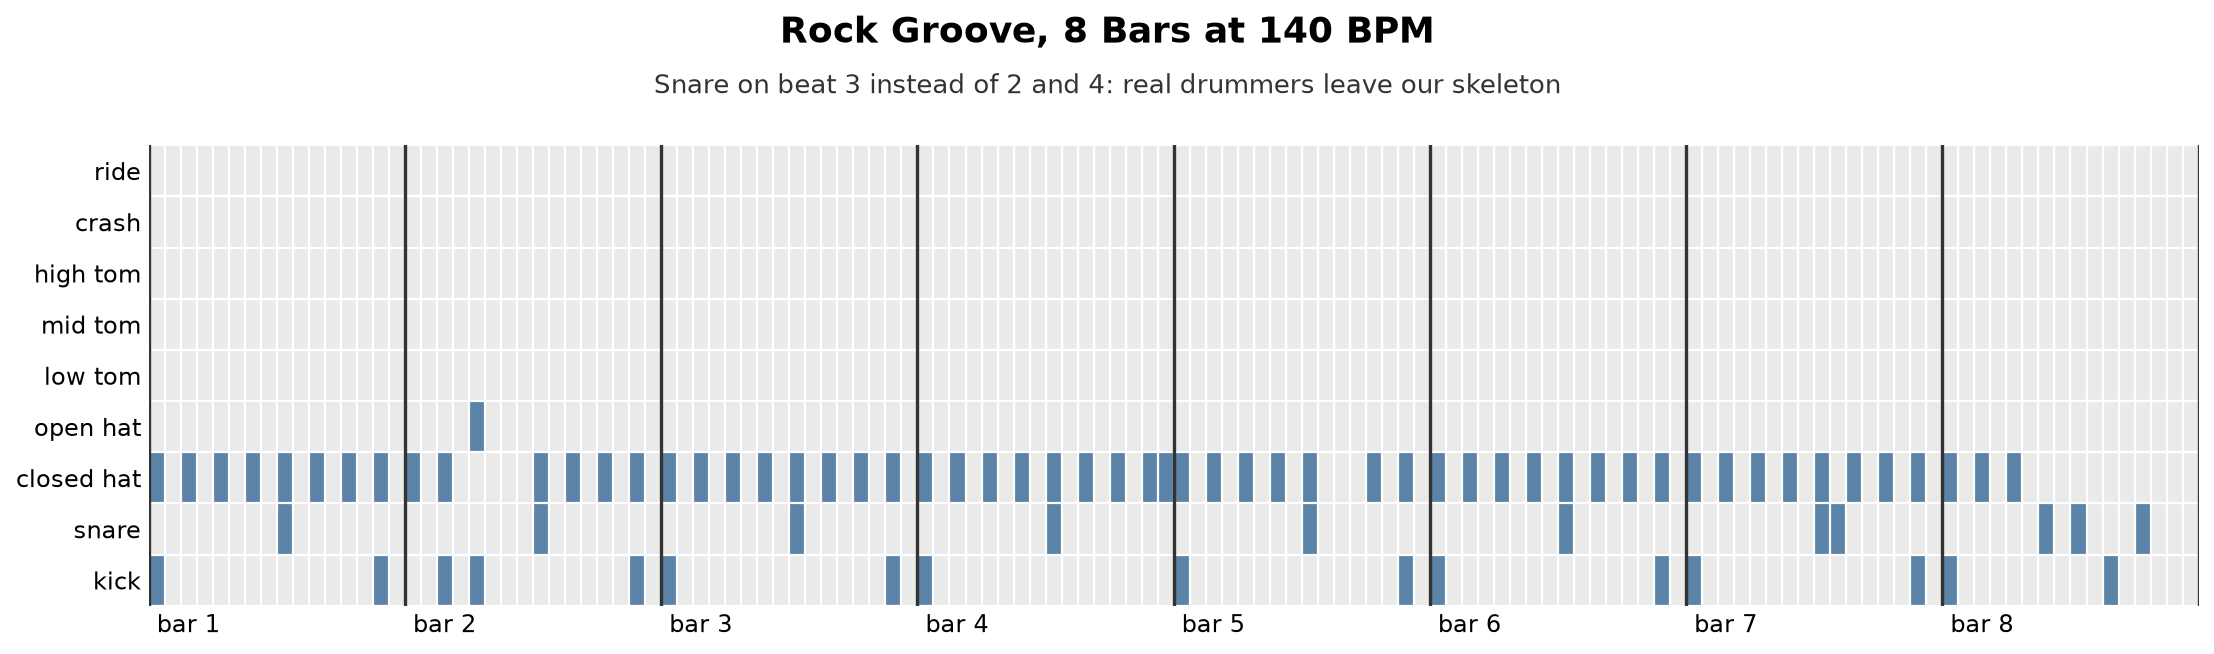

In [6]:
display(Image(filename="data_analysis/figures/example_rock.png", width=900))
play("example_rock", folder=OUTPUT_DIR.parent / "data_analysis" / "audio")

# 3. Rule baseline (A)

System A answers: *what can we do without learning?* On top of the skeleton, every decoration cell gets a
hand-written chance of a hit, depending only on the drum and the position in the bar, sampled independently:

- closed hat on every 8th note (90%), occasionally on the 16ths in between (10%);
- open hat on the "&" of 4, leading into the next bar (30%); a hat is open or closed, not both;
- toms on the last three 16ths of a bar (5% each), crash on beat 1 (25%), ride on the beats (30%).

The probabilities were **set once** so that A's decoration density is close to d_GMD (about 10 hits per bar),
**then frozen**. A was not tuned on anything else, in particular not on bar-to-bar change.

In [7]:
counts = ["1", "e", "&", "a", "2", "e", "&", "a", "3", "e", "&", "a", "4", "e", "&", "a"]
p = pd.DataFrame(rule_probabilities()[:, list(DECORATION_CHANNELS)], index=counts,
                 columns=[CLASSES[c] for c in DECORATION_CHANNELS])
display(p.T.replace(0, "").style.format(lambda v: f"{v:.2f}" if v != "" else ""))

a_loops = np.stack([rule_loop(s) for s in SEEDS])
assert np.array_equal(a_loops, LOOPS["A rules"])  # same seeds give the same loops as the saved results
print(f"A: {density(a_loops):.2f} decoration hits per bar, against d_GMD = {d_gmd:.2f}")

,1,e,&,a,2,e,&,a,3,e,&,a,4,e,&,a
closed_hat,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10,0.90,0.10
open_hat,,,,,,,,,,,,,,,0.30,
low_tom,,,,,,,,,,,,,,0.05,0.05,0.05
mid_tom,,,,,,,,,,,,,,0.05,0.05,0.05
high_tom,,,,,,,,,,,,,,0.05,0.05,0.05
crash,0.25,,,,,,,,,,,,,,,
ride,0.30,,,,0.30,,,,0.30,,,,0.30,,,


A: 9.88 decoration hits per bar, against d_GMD = 9.96


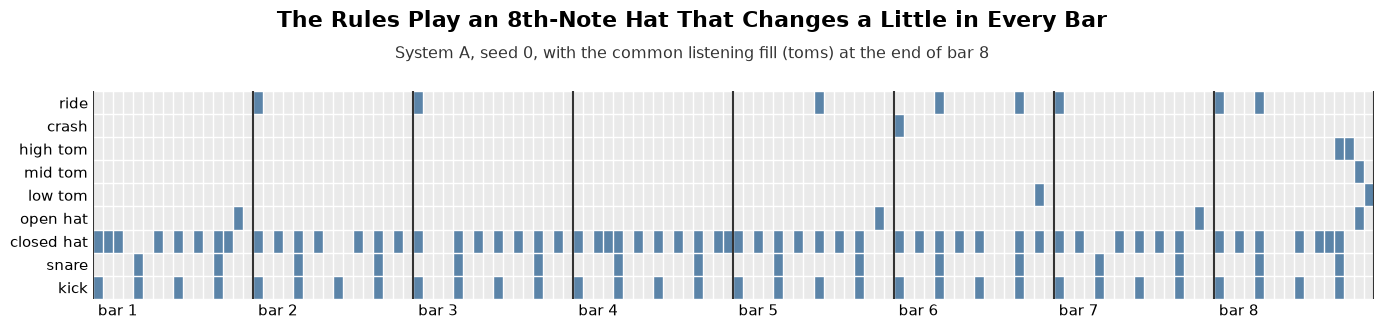

**A, seed 0**

**A, seed 1**

In [8]:
show_loop(add_fill(a_loops[0]), "The Rules Play an 8th-Note Hat That Changes a Little in Every Bar",
          subtitle="System A, seed 0, with the common listening fill (toms) at the end of bar 8")
for s in LISTEN_SEEDS:
    play(f"A_seed{s}", f"A, seed {s}")

# 4. Learned model

**The model predicts the next 16th note of human drumming from everything played so far.** It learns how drummers
continue a groove, not what good fitness music is; the fitness part comes from the constraint in section 5.

```
 previous step (9 drums, 0/1) ─┐
                               ├─► LSTM layers ─► 512 scores ─► softmax ─► sample one drum combination ─┐
 position in bar (one-hot 16) ─┘      (state carried across all 8 bars)                                  │
          ▲                                                                                              │
          └──────────────────────────── fed back as the next input ──────────────────────────────────────┘
```

- **Output.** We compared two output types: *bernoulli* (an independent hit chance per drum) and *categorical*
  (one choice among all 2^9 = 512 drum combinations per step, as Drums RNN). The categorical output can learn which
  drums go together and which exclude each other (an open and a closed hat); drummers use only 145 of the 512.
- **Loss.** Both are trained on the negative log-likelihood of the real next step, in nats per step, so they
  compare directly. This proper scoring rule keeps probabilities calibrated, so sampled loops get a realistic
  density without any tuning.
- **Sizes.** 2x128, 2x256 and 3x256 (the Drums RNN size), each output type x size trained once (seed 0); the lowest
  validation loss wins.
- **Training.** 8-bar windows (128 steps, the same length as the generated loops), stride 2 bars: 7,212 training
  windows. Teacher forcing, Adam (learning rate 0.001), batch 64, gradient clipping 3, early stopping on the
  validation loss (patience 15), deterministic GPU kernels.

| | Drums RNN (`drum_kit`) | Ours |
|---|---|---|
| Drums, time step | 9 drums, 16th notes | same |
| Output | one of 512 combinations | both that and 9 independent drums, compared |
| Inputs | previous combination (one-hot 512), 6-bit position counter | previous drums (9, same information), one-hot position (16) |
| Network | 3 x 256 LSTM, attention over 32 steps | 2x128 to 3x256 compared; no attention |
| Training | dropout 0.5, lr 0.001, batch 128, clipping 3 | dropout 0.2-0.5, lr 0.001, batch 64, clipping 3 |

In [9]:
selection = pd.read_csv(RESULTS / "model_selection.csv")
display(selection.style.format({"validation loss": "{:.3f}", "parameters": "{:,}"}).hide(axis="index"))

output,size,parameters,best epoch,validation loss
categorical,Drums RNN 3x256,"1,474,048",63,1.430
categorical,medium 2x256,"947,712",44,1.448
categorical,small 2x128,"277,504",57,1.475
bernoulli,medium 2x256,"818,441",31,1.500
bernoulli,small 2x128,"212,617",46,1.516
bernoulli,Drums RNN 3x256,"1,344,777",35,1.523


The **categorical 3x256** model (the Drums RNN configuration) has the lowest validation loss, and every categorical
model beats every bernoulli model: predicting the drums of a step jointly is better than predicting them
independently. This configuration was then trained with **5 seeds** (0-4) to show how much the results depend on
the training run; B, C and D are reported as the mean and range over those 5 models.

seed,best epoch,validation loss
0,63,1.430
1,43,1.432
2,42,1.423
3,31,1.416
4,52,1.423


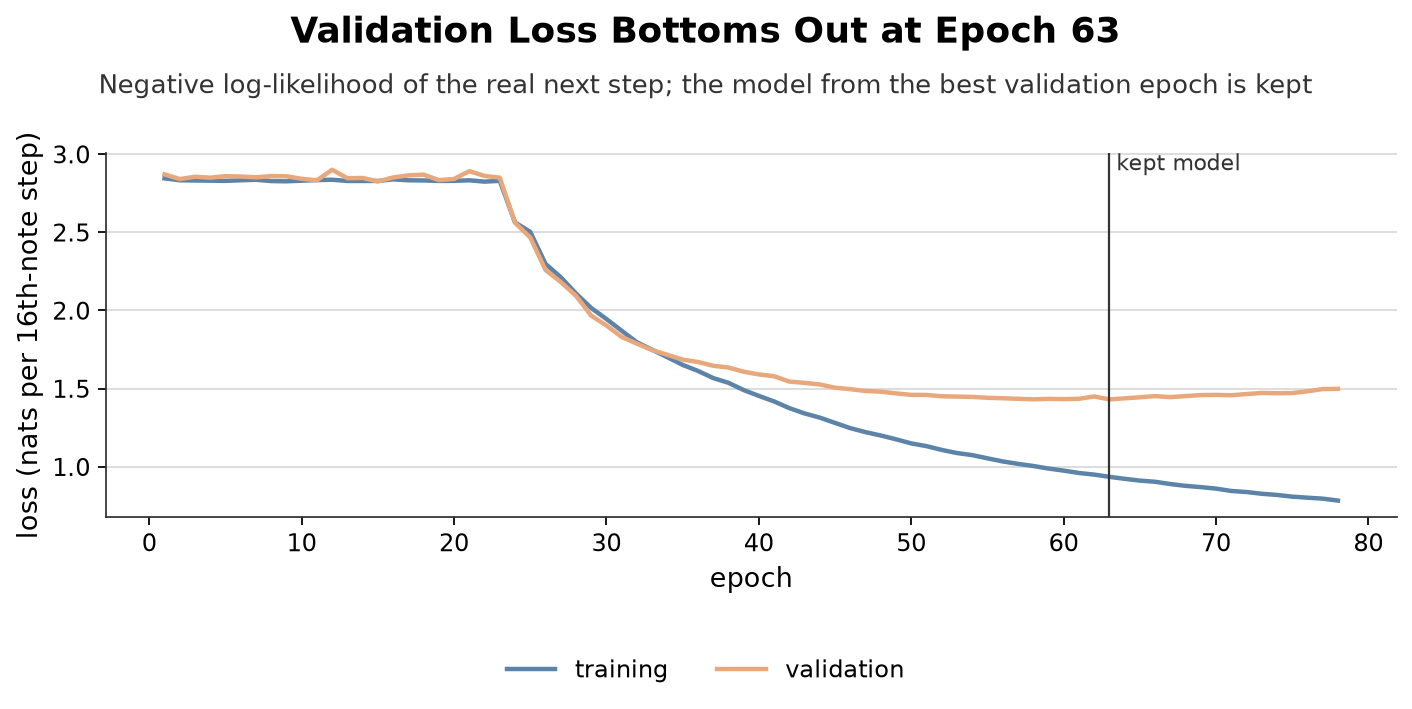

In [10]:
training = pd.read_csv(RESULTS / "training.csv")
display(training[["seed", "best epoch", "validation loss"]].style.format({"validation loss": "{:.3f}"})
        .hide(axis="index"))
display(Image(filename=str(RESULTS / "loss_curve.png"), width=750))

The validation loss is about 1.42-1.43 nats per step across seeds, so the training run matters little for the
loss. (Test loss is reported once, at the end of section 6.) Validation loss measures how well the model predicts
unseen human drumming, not musical quality.

**Generation.** Start from an all-zero input, sample one combination per step at temperature 1.0, feed it back, and
carry the LSTM state across all 8 bars (never reset at bar lines). In **free mode (B)** the model chooses every drum.
The animation below shows the real model (training seed 0, listening seed 0) writing a loop one 16th note at a time,
first free, then constrained.

![How the model writes a loop](output/animation/generation.gif)

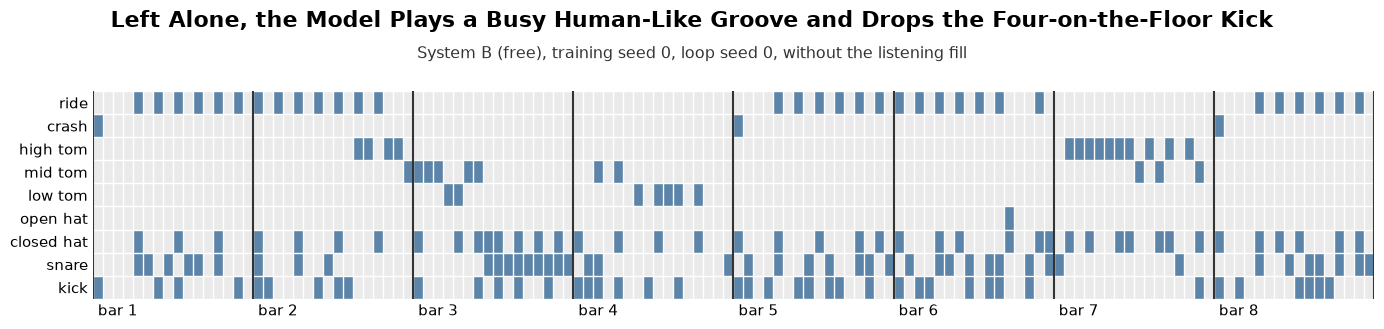

**B, seed 0 (with the listening fill)**

**B, seed 1 (with the listening fill)**

In [11]:
show_loop(LOOPS["B free|0"][0], "Left Alone, the Model Plays a Busy Human-Like Groove and Drops the Four-on-the-Floor Kick",
          subtitle="System B (free), training seed 0, loop seed 0, without the listening fill")
for s in LISTEN_SEEDS:
    play(f"B_seed{s}", f"B, seed {s} (with the listening fill)")

# 5. Adding constraints (C)

TODO

# 6. Experiment

TODO

# 7. Reflection

TODO